In [13]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uciml/iris/Iris.csv
/kaggle/input/datasets/uciml/iris/database.sqlite


# 1. Imports

In [14]:
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

np.random.seed(42)

In [15]:
import os
for dirname, _, filenames in os.walk("/kaggle/input"):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/uciml/iris/Iris.csv
/kaggle/input/datasets/uciml/iris/database.sqlite


# 2.Load and Split Data

In [16]:
df = pd.read_csv("/kaggle/input/datasets/uciml/iris/Iris.csv")
print(df.shape)
print(df["Species"].value_counts())

X = df.drop(columns=["Id", "Species"]).values
y = pd.factorize(df["Species"])[0]      # setosa=0, versicolor=1, virginica=2

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

n_features, n_classes = X_train.shape[1], 3
print("Train:", X_train.shape, "Test:", X_test.shape)

(150, 6)
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64
Train: (120, 4) Test: (30, 4)


# 3.Models from Scratch

In [17]:
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

class SoftmaxRegression:
    def __init__(self, n_features, n_classes, l2=1e-3):
        self.p = {"W": np.zeros((n_features, n_classes)), "b": np.zeros(n_classes)}
        self.l2, self.k = l2, n_classes

    def predict_proba(self, X):
        return softmax(X @ self.p["W"] + self.p["b"])

    def loss_grads(self, X, y):
        n = len(X)
        P = self.predict_proba(X)
        Y = np.eye(self.k)[y]
        loss = -np.mean(np.log(P[np.arange(n), y] + 1e-12)) + 0.5 * self.l2 * np.sum(self.p["W"] ** 2)
        d = (P - Y) / n
        grads = {"W": X.T @ d + self.l2 * self.p["W"], "b": d.sum(axis=0)}
        return loss, grads

class NeuralNetwork:
    def __init__(self, n_features, n_classes, hidden=16, l2=1e-3, seed=42):
        rng = np.random.RandomState(seed)
        self.p = {
            "W1": rng.randn(n_features, hidden) * np.sqrt(2 / n_features), "b1": np.zeros(hidden),
            "W2": rng.randn(hidden, n_classes) * np.sqrt(2 / hidden),      "b2": np.zeros(n_classes),
        }
        self.l2, self.k = l2, n_classes

    def forward(self, X):
        Z1 = X @ self.p["W1"] + self.p["b1"]
        A1 = np.maximum(0, Z1)
        return Z1, A1, softmax(A1 @ self.p["W2"] + self.p["b2"])

    def predict_proba(self, X):
        return self.forward(X)[2]

    def loss_grads(self, X, y):
        n = len(X)
        Z1, A1, P = self.forward(X)
        Y = np.eye(self.k)[y]
        reg = 0.5 * self.l2 * (np.sum(self.p["W1"] ** 2) + np.sum(self.p["W2"] ** 2))
        loss = -np.mean(np.log(P[np.arange(n), y] + 1e-12)) + reg
        d2 = (P - Y) / n
        dA1 = d2 @ self.p["W2"].T
        dZ1 = dA1 * (Z1 > 0)
        grads = {
            "W2": A1.T @ d2 + self.l2 * self.p["W2"], "b2": d2.sum(axis=0),
            "W1": X.T @ dZ1 + self.l2 * self.p["W1"], "b1": dZ1.sum(axis=0),
        }
        return loss, grads

# 4.Training and Metrics Functions

In [18]:
def train(model, optimizer, X, y, epochs, batch_size):
    n = len(X)
    history = []
    for ep in range(epochs):
        idx = np.random.permutation(n)
        for s in range(0, n, batch_size):
            b = idx[s:s + batch_size]
            _, grads = model.loss_grads(X[b], y[b])
            optimizer.step(model.p, grads)
        history.append(model.loss_grads(X, y)[0])
    return history

def metrics(y_true, y_pred):
    return {
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall":    recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1":  f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

# 5. Stochastic Gradient Descent (SGD)

In [19]:
OPT_NAME = "Stochastic Gradient Descent (SGD)"
EPOCHS, BATCH = 100, 1                 # one update per single sample

class SGD:
    def __init__(self, lr):
        self.lr = lr
    def step(self, params, grads):
        for k in params:
            params[k] -= self.lr * grads[k]

make_optimizer = lambda: SGD(lr=0.01)

# 6.Train the Models

In [20]:
t0 = time.time()

# Random Forest (no optimizer needed)
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

# Softmax Regression and Neural Network, trained with the chosen optimizer
softmax_model = SoftmaxRegression(n_features, n_classes)
nn_model      = NeuralNetwork(n_features, n_classes)

hist_softmax = train(softmax_model, make_optimizer(), X_train, y_train, EPOCHS, BATCH)
hist_nn      = train(nn_model,      make_optimizer(), X_train, y_train, EPOCHS, BATCH)

print(f"Training time: {time.time() - t0:.1f} s")
print(f"Final loss  Softmax: {hist_softmax[-1]:.4f} | NN: {hist_nn[-1]:.4f}")

Training time: 2.7 s
Final loss  Softmax: 0.1266 | NN: 0.0698


# 7.Hard Voting and Soft Voting

In [21]:
P_rf      = rf.predict_proba(X_test)
P_softmax = softmax_model.predict_proba(X_test)
P_nn      = nn_model.predict_proba(X_test)

pred_rf, pred_softmax, pred_nn = P_rf.argmax(1), P_softmax.argmax(1), P_nn.argmax(1)

# Hard voting: majority class of the 3 models (if all three disagree, use Random Forest)
votes = np.vstack([pred_rf, pred_softmax, pred_nn])
pred_hard = np.array([
    np.bincount(votes[:, i], minlength=n_classes).argmax()
    if np.bincount(votes[:, i], minlength=n_classes).max() > 1 else pred_rf[i]
    for i in range(votes.shape[1])
])

# Soft voting: average of the predicted probabilities
pred_soft = ((P_rf + P_softmax + P_nn) / 3).argmax(1)

# 8.Results Table

In [22]:
rows = {
    "Random Forest":      (pred_rf,      None),
    "Softmax Regression": (pred_softmax, hist_softmax[-1]),
    "Neural Network":     (pred_nn,      hist_nn[-1]),
    "Hard Voting":        (pred_hard,    None),
    "Soft Voting":        (pred_soft,    None),
}
table = pd.DataFrame(
    {name: {**metrics(y_test, pred), "Final Train Loss": loss} for name, (pred, loss) in rows.items()}
).T.round(4)
table

,Accuracy,Precision,Recall,Macro F1,Final Train Loss
Random Forest,0.9000,0.9024,0.9000,0.8997,NaN
Softmax Regression,0.9333,0.9333,0.9333,0.9333,0.1266
Neural Network,0.9667,0.9697,0.9667,0.9666,0.0698
Hard Voting,0.9333,0.9333,0.9333,0.9333,NaN
Soft Voting,0.9667,0.9697,0.9667,0.9666,NaN


# 9.Loss Curves and Confusion Matrix

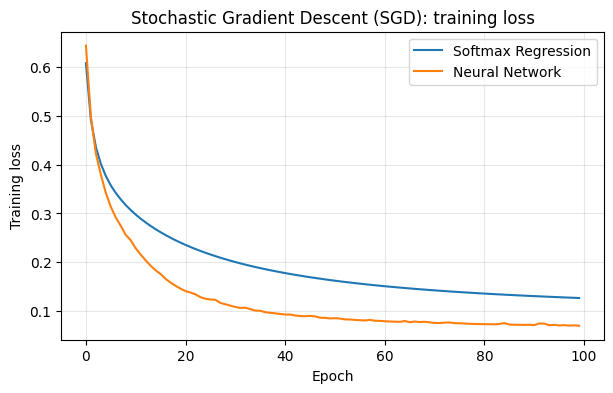

Confusion matrix (Soft Voting):
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


In [24]:
plt.figure(figsize=(7, 4))
plt.plot(hist_softmax, label="Softmax Regression")
plt.plot(hist_nn, label="Neural Network")
plt.xlabel("Epoch"); plt.ylabel("Training loss")
plt.title(f"{OPT_NAME}: training loss")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

print("Confusion matrix (Soft Voting):")
print(confusion_matrix(y_test, pred_soft))